# Ejercicio 2. Verificación numérica

Este cuaderno acompaña al informe [`ejercicio-02.md`](ejercicio-02.md). Ejecuta la búsqueda binaria, vigila el invariante y el potencial, compara con un oráculo lineal y genera la Figura 1 (`ejercicio-02.png`). Las secciones siguen la numeración del informe.

Se cuenta como una comparación cada llamada a un comparador de tres resultados ($-1$, $0$, $1$), como en la conferencia 5, sección 3. El comparador Python implementa esa operación mediante dos predicados. Para reproducir el cuaderno hace falta Python 3 y `matplotlib`.

In [1]:
import math
from itertools import combinations_with_replacement

import matplotlib.pyplot as plt


def bound(n):
    # n.bit_length() = ceil(log2(n + 1)); evita redondeos de punto flotante.
    return n.bit_length()

## 1. Formulación

Entrada: un arreglo no decreciente $A$ y un valor $x$ de un orden total. Salida: cualquier índice donde aparezca $x$, o $-1$ si no aparece. Se permiten repetidos y el arreglo vacío. El oráculo recorre el arreglo sin usar la búsqueda binaria ni sus fórmulas.

In [2]:
def oracle(A, x):
    for i, value in enumerate(A):
        if value == x:
            return i
    return -1


def validate_result(A, x, result):
    expected = oracle(A, x)
    if expected == -1:
        assert result == -1, (A, x, result)
    else:
        assert 0 <= result < len(A), (A, x, result)
        assert A[result] == x, (A, x, result)

## 2. Algoritmo e invariante

El algoritmo siguiente es el mismo del informe. El comparador se puede sustituir para contar llamadas y observar cada paso sin modificar el algoritmo.

Invariante: $0\le lo\le hi\le n$ y, si $x$ aparece en $A$, alguna aparición está en $A[lo:hi]$. El monitor verifica también la propiedad más fuerte de que todo valor anterior a `lo` es menor que $x$ y todo valor desde `hi` es mayor que $x$.

In [3]:
def compare(x, y):
    return (x > y) - (x < y)  # -1, 0 o 1


def binary_search(A, x, compare=compare):
    lo, hi = 0, len(A)
    while lo < hi:
        m = lo + (hi - lo) // 2
        r = compare(x, A[m])
        if r == 0:
            return m
        if r < 0:
            hi = m
        else:
            lo = m + 1
    return -1

In [4]:
def run_monitored(A, x):
    lo, hi = 0, len(A)
    trace = []

    def invariant():
        assert 0 <= lo <= hi <= len(A)
        if x in A:
            assert x in A[lo:hi]
        assert all(value < x for value in A[:lo])
        assert all(value > x for value in A[hi:])

    def monitored_compare(query, value):
        nonlocal lo, hi
        invariant()
        assert lo < hi
        m = lo + (hi - lo) // 2
        assert query == x and value == A[m]
        d = hi - lo
        r = compare(query, value)
        step = dict(lo=lo, hi=hi, m=m, value=value, r=r,
                    phi=d, psi=bound(d))
        if r != 0:
            if r < 0:
                hi = m
            else:
                lo = m + 1
            new_length = hi - lo
            assert 0 <= new_length <= d // 2 < d
            assert bound(new_length) <= bound(d) - 1
            invariant()
            step.update(next_lo=lo, next_hi=hi,
                        next_phi=new_length, next_psi=bound(new_length))
        trace.append(step)
        return r

    invariant()
    result = binary_search(A, x, monitored_compare)
    validate_result(A, x, result)
    assert len(trace) <= bound(len(A))
    if result == -1:
        assert lo == hi
    else:
        assert trace[-1]['r'] == 0 and result == trace[-1]['m']
    return result, trace


example_A = list(range(2, 15, 2))
example_result, example_trace = run_monitored(example_A, 13)
print('A =', example_A, ' x = 13')
for t, step in enumerate(example_trace, 1):
    sign = '<' if step['r'] < 0 else '>'
    print(f"{t}: [{step['lo']}, {step['hi']})  m={step['m']}  "
          f"A[m]={step['value']}  x {sign} A[m]  -> "
          f"[{step['next_lo']}, {step['next_hi']})  "
          f"Phi={step['next_phi']}")
print('resultado:', example_result)
assert example_result == -1
assert [(p['lo'], p['hi'], p['m'], p['value'],
         p['next_lo'], p['next_hi']) for p in example_trace] == [
    (0, 7, 3, 8, 4, 7), (4, 7, 5, 12, 6, 7), (6, 7, 6, 14, 6, 6)]

A = [2, 4, 6, 8, 10, 12, 14]  x = 13
1: [0, 7)  m=3  A[m]=8  x > A[m]  -> [4, 7)  Phi=3
2: [4, 7)  m=5  A[m]=12  x > A[m]  -> [6, 7)  Phi=1
3: [6, 7)  m=6  A[m]=14  x < A[m]  -> [6, 6)  Phi=0
resultado: -1


## 3. Potencial, terminación y costo

$\Phi=hi-lo$ cae como máximo a $\lfloor\Phi/2\rfloor$ en una vuelta sin éxito. El potencial entero $\Psi=\lceil\log_2(\Phi+1)\rceil$ cae al menos una unidad. Se verifican las dos ramas para todas las longitudes desde 1 hasta 10 000; después se imprimen los potenciales del ejemplo del informe.

In [5]:
for d in range(1, 10_001):
    m = d // 2
    for next_length in [m, d - m - 1]:
        assert 0 <= next_length <= d // 2 < d
        assert bound(next_length) <= bound(d) - 1
print('ok: reducción de ambos potenciales para longitudes de 1 a 10 000')

example_phi = [len(example_A)] + [p['next_phi'] for p in example_trace]
example_psi = [bound(d) for d in example_phi]
assert example_phi == [7, 3, 1, 0]
assert example_psi == [3, 2, 1, 0]
print('Phi:', example_phi)
print('Psi:', example_psi)

for n in range(1, 257):
    A = list(range(n))
    result, trace = run_monitored(A, A[n // 2])
    assert result == n // 2 and len(trace) == 1
print('ok: el mejor caso es una comparación para 1 <= n <= 256')

ok: reducción de ambos potenciales para longitudes de 1 a 10 000
Phi: [7, 3, 1, 0]
Psi: [3, 2, 1, 0]
ok: el mejor caso es una comparación para 1 <= n <= 256


## 4. Cota de información y optimalidad

Se fija $A=[2,4,\ldots,2n]$. El valor $2g+1$ representa el hueco $g$, para $g=0,\ldots,n$ (también para $n=0$). Se registra el camino como una secuencia de pares (índice consultado, respuesta). Todos los huecos deben seguir caminos distintos. Su longitud máxima debe coincidir con la cota $\lceil\log_2(n+1)\rceil$.

La prueba matemática del informe establece la cota mínima para cualquier algoritmo del modelo; esta enumeración comprueba cómo la alcanza la implementación.

In [6]:
worst_cases = []
gap_searches = 0
for n in range(257):
    A = list(range(2, 2 * n + 1, 2))
    paths = set()
    worst_case = 0
    for g in range(n + 1):
        result, trace = run_monitored(A, 2 * g + 1)
        assert result == -1
        path = tuple((p['m'], p['r']) for p in trace)
        assert path not in paths, (n, g, path)
        paths.add(path)
        worst_case = max(worst_case, len(trace))
        gap_searches += 1
    assert len(paths) == n + 1
    assert worst_case == bound(n), (n, worst_case, bound(n))
    worst_cases.append(worst_case)

assert gap_searches == 33_153
print(f'ok: {gap_searches:,} búsquedas; todos los huecos tienen caminos distintos')
print('ok: peor caso = ceil(log2(n + 1)) para 0 <= n <= 256')
print()
print(f"{'n':>5} {'huecos':>7} {'peor caso':>10} {'cota':>6}")
for n in [0, 1, 2, 3, 7, 8, 15, 16, 31, 32, 255, 256]:
    print(f'{n:5} {n + 1:7} {worst_cases[n]:10} {bound(n):6}')

ok: 33,153 búsquedas; todos los huecos tienen caminos distintos
ok: peor caso = ceil(log2(n + 1)) para 0 <= n <= 256

    n  huecos  peor caso   cota
    0       1          0      0
    1       2          1      1
    2       3          2      2
    3       4          2      2
    7       8          3      3
    8       9          4      4
   15      16          4      4
   16      17          5      5
   31      32          5      5
   32      33          6      6
  255     256          8      8
  256     257          9      9


## 5. Casos de prueba

Se enumeran todos los arreglos no decrecientes de longitudes 0 a 9 sobre $\{0,2,4,6\}$, y todas las consultas enteras de $-1$ a 7. Esto incluye vacíos, extremos, presentes, ausentes y repetidos. Se valida cada resultado con el oráculo lineal y se vigilan los invariantes, los potenciales y la cota superior durante la ejecución.

In [7]:
array_count = 0
duplicate_searches = 0
for n in range(10):
    for A in combinations_with_replacement([0, 2, 4, 6], n):
        array_count += 1
        for x in range(-1, 8):
            run_monitored(A, x)
            duplicate_searches += 1

assert array_count == math.comb(13, 4) == 715
assert duplicate_searches == 6_435
print(f'ok: {array_count} arreglos y {duplicate_searches:,} búsquedas')
print('ok: oráculo, invariante, ambos potenciales y cota superior')

ok: 715 arreglos y 6,435 búsquedas
ok: oráculo, invariante, ambos potenciales y cota superior


## Figura 1

A la izquierda, el peor caso medido y la cota de información para $0\le n\le256$. A la derecha, los dos potenciales en la traza del ejemplo. La imagen se guarda como `ejercicio-02.png`, que es la que incluye el informe.

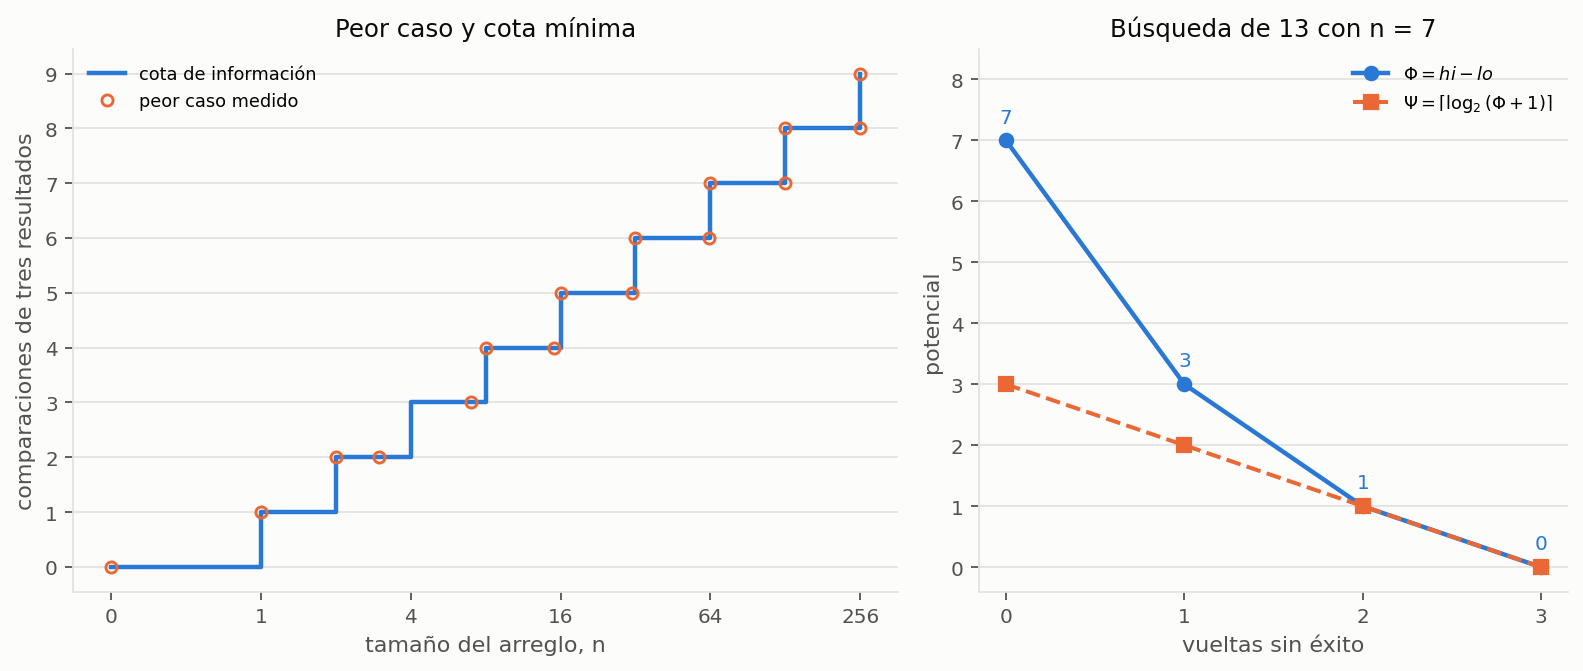

In [8]:
blue, orange = '#2a78d6', '#eb6834'
ink, secondary_ink, grid_color, background = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), dpi=160,
                         gridspec_kw={'width_ratios': [1.4, 1]})
fig.patch.set_facecolor(background)
ax, ax_p = axes
ns = list(range(257))
ax.step(ns, [bound(n) for n in ns], where='post', color=blue,
        lw=2, label='cota de información')
samples = [0, 1, 2, 3, 7, 8, 15, 16, 31, 32, 63, 64, 127, 128, 255, 256]
ax.plot(samples, [worst_cases[n] for n in samples], 'o', ms=5,
        mfc='none', mec=orange, mew=1.3, label='peor caso medido')
ax.set_xscale('symlog', linthresh=1, base=2)
ax.set_xticks([0, 1, 4, 16, 64, 256], ['0', '1', '4', '16', '64', '256'])
ax.set_yticks(range(10))
ax.set_xlabel('tamaño del arreglo, n')
ax.set_ylabel('comparaciones de tres resultados')
ax.set_title('Peor caso y cota mínima', color=ink, fontsize=11)
ax.legend(frameon=False, fontsize=8, loc='upper left')

iterations = list(range(len(example_phi)))
ax_p.plot(iterations, example_phi, 'o-', color=blue, lw=2,
          label=r'$\Phi = hi-lo$')
ax_p.plot(iterations, example_psi, 's--', color=orange, lw=1.8,
          label=r'$\Psi = \lceil\log_2(\Phi+1)\rceil$')
for t, d in enumerate(example_phi):
    ax_p.annotate(str(d), (t, d), xytext=(0, 8),
                  textcoords='offset points', ha='center', color=blue, fontsize=9)
ax_p.set_xticks(iterations)
ax_p.set_ylim(-0.4, 8.5)
ax_p.set_xlabel('vueltas sin éxito')
ax_p.set_ylabel('potencial')
ax_p.set_title('Búsqueda de 13 con n = 7', color=ink, fontsize=11)
ax_p.legend(frameon=False, fontsize=8, loc='upper right')

for axis in axes:
    axis.set_facecolor(background)
    axis.grid(axis='y', color=grid_color, lw=0.8)
    axis.minorticks_off()
    for side in ['top', 'right']:
        axis.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        axis.spines[side].set_color(grid_color)
    axis.tick_params(colors=secondary_ink, labelsize=9)
    axis.xaxis.label.set_color(secondary_ink)
    axis.yaxis.label.set_color(secondary_ink)

fig.tight_layout()
fig.savefig('ejercicio-02.png', facecolor=background)
plt.show()

## 6. Conclusiones

El invariante demuestra correctitud parcial. El potencial $\Phi=hi-lo$ demuestra terminación y su reducción a la mitad da la cota superior. Los $n+1$ huecos dan la misma cota mínima de información, por lo que el peor caso es exactamente $\lceil\log_2(n+1)\rceil$ comparaciones. La versión iterativa usa memoria auxiliar constante.

Los casos enumerados comprueban la implementación; las demostraciones del informe cubren todos los tamaños.

In [9]:
assert worst_cases == [bound(n) for n in range(257)]
print('Todas las comprobaciones finalizaron correctamente.')
print(f'Búsquedas exhaustivas con repetidos: {duplicate_searches:,}')
print(f'Búsquedas exhaustivas en huecos: {gap_searches:,}')
print('Figura guardada en ejercicio-02.png')

Todas las comprobaciones finalizaron correctamente.
Búsquedas exhaustivas con repetidos: 6,435
Búsquedas exhaustivas en huecos: 33,153
Figura guardada en ejercicio-02.png
